# Phase 1: Legal Language Model Pre-training - Legal Transformer

## Task
Train a legal language model from scratch. Given a 512-word prompt from a legal document, the model writes the next 128 words. Scored with BERTScore F1 (main) and ROUGE-L F1.

Author: Preet Patel (261110043)

Model: a decoder-only Transformer with causal self-attention, rotary position embeddings (RoPE), a GELU feed-forward layer and tied embeddings. dim 896, 27 layers, 14 heads, about 271M parameters. Generation uses a key/value cache.

## Input
- Phase-1 legal text from the Hugging Face dataset (needs the HF_TOKEN secret): up to 25,000 documents per source, 100,000 in total.
- Official Phase-1 test prompts.
- Optional: a saved checkpoint and tokenizer to resume from (RESUME_CHECKPOINT_PATH, RESUME_TOKENIZER_PATH).

## Flow of the notebook (from input to output)
1. Set up the environment, memory helpers and checkpoint saving.
2. Set the training settings and output folders.
3. Log in and find the data files.
4. Stream the legal documents piece by piece with low memory.
5. Load the official test prompts.
6. Train a byte-level BPE tokenizer (about 12,000 tokens) from scratch on the legal text.
7. Build the Legal Transformer and check its parameter count and starting loss.
8. Define the train / validation split functions.
9. Define the dataset, the training loop (warm-up + cosine learning rate, gradient accumulation, mixed precision, label smoothing, early stopping), optional word2vec start for the embeddings, generation with the key/value cache, and evaluation.
10. Create the 90/10 random train / validation split.
11. Run a quick speed and memory test.
12. Train for up to 8,500 updates, keep the 3 best checkpoints, compare generation settings (greedy, sampling, top-k) on validation prompts, and pick the checkpoint with the best generated text.
13. Plot training vs validation loss.
14. Save the chosen checkpoint, the tokenizer and the score record.
15. Generate continuations for the test prompts with the chosen setting and package them.

## Output
- Checkpoint package (.pt file with the weights and settings) and tokenizer (.json).
- Score record with validation loss, perplexity, BERTScore and the chosen generation setting.
- submission.zip with the test continuations.

In [5]:
# Environment setup and memory helper functions
import os, json, gc, ctypes, random, zipfile, resource
os.environ.setdefault("PYTORCH_ENABLE_MPS_FALLBACK", "1")
os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")
from pathlib import Path
from collections import Counter

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW

N_PHASES = 13
# It takes n (number) and msg (message) as input, prints which step of the notebook is running and returns nothing.
def phase_marker(n, msg):
    print(f"\n[Transformer | {n}/{N_PHASES}] {msg}")

# It returns how much RAM this process is using (GB).
def host_ram_gb():
    return resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / (1024 ** 2)

# It takes tag (label) as input, prints the current RAM usage with a label and returns nothing.
def log_ram(tag):
    print(f"    (ram) {tag}: {host_ram_gb():.2f} GB")

# It frees unused CPU and GPU memory and returns nothing.
def release_memory():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    try:
        ctypes.CDLL("libc.so.6").malloc_trim(0)
    except Exception:
        pass

# It takes net (model) as input, uses all available GPUs if there is more than one and returns the model, wrapped for several GPUs if available.
def enable_multi_gpu(net):
    if torch.cuda.is_available() and torch.cuda.device_count() > 1:
        print(f"    multi-GPU: using {torch.cuda.device_count()} GPUs via nn.DataParallel")
        return nn.DataParallel(net)
    return net

# It takes net (model) as input, gets the plain model back from the multi-GPU wrapper and returns the plain model.
def strip_replica(net):
    return net.module if isinstance(net, nn.DataParallel) else net

# It takes net (model) and path (file path) as input, saves the model weights together with its settings and returns nothing.
def save_checkpoint_package(net, path):
    torch.save({
        "state_dict": {k: v.detach().cpu().clone() for k, v in strip_replica(net).state_dict().items()},
        "config": {
            "vocab_size": Settings.VOCAB_SIZE,
            "dim": Settings.MODEL_DIM,
            "n_layers": Settings.MODEL_LAYERS,
            "n_heads": Settings.MODEL_HEADS,
            "dropout": Settings.DROPOUT,
            "tied": Settings.TIE_EMBEDDINGS,
        },
    }, path)

phase_marker(1, "Environment ready")
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
torch.backends.cudnn.benchmark = True
print(f"device = {device}")
if device.type == "mps":
    print("note: Apple GPU (MPS) selected -- unified memory is shared with system RAM, "
          "so watch Settings.BATCH_SIZE/MODEL_DIM below if you see slowdowns from memory "
          "pressure rather than a hard OOM crash (there is no MPS equivalent of CUDA's "
          "hard VRAM ceiling).")
if torch.cuda.is_available():
    print(f"gpu    = {torch.cuda.get_device_name(0)}")
    print(f"vram   = {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")
    if torch.cuda.device_count() > 1:
        print(f"note: {torch.cuda.device_count()} GPUs detected -- consider raising "
              f"Settings.BATCH_SIZE / Settings.GEN_BATCH_SIZE (roughly x{torch.cuda.device_count()}) "
              f"below so each GPU gets a full batch.")
log_ram("after setup")


[Transformer | 1/13] Environment ready
device = cuda
gpu    = Tesla T4
vram   = 15.6 GB
note: 2 GPUs detected -- consider raising Settings.BATCH_SIZE / Settings.GEN_BATCH_SIZE (roughly x2) below so each GPU gets a full batch.
    (ram) after setup: 0.58 GB


In [6]:
# Set training settings and output folders
phase_marker(2, "Preparing run settings + output folders")
WORK_DIR = "/kaggle/working" if os.path.isdir("/kaggle") else os.path.join(os.getcwd(), "kaggle_working")
CKPT_DIR = os.path.join(WORK_DIR, "checkpoints")
OUT_DIR = os.path.join(WORK_DIR, "outputs")
for d in (CKPT_DIR, OUT_DIR):
    Path(d).mkdir(parents=True, exist_ok=True)

class Settings:
    PROMPT_TOKENS = 512
    CONT_TOKENS = 128
    SEQ_TOKENS = PROMPT_TOKENS + CONT_TOKENS

    VOCAB_SIZE = 12000

    DOCS_PER_SOURCE_CAP = 25000
    TOTAL_DOCS_CAP = 100000

    MODEL_DIM = 896
    MODEL_LAYERS = 27
    MODEL_HEADS = 14
    TIE_EMBEDDINGS = True

    BATCH_SIZE = 4
    GRAD_ACCUM_STEPS = 4
    PEAK_LR = 3e-4
    WARMUP_FRAC = 0.06
    MIN_LR_FRAC = 0.10
    WEIGHT_DECAY = 0.05
    GRAD_CLIP = 1.0
    SEED = 7

    DROPOUT = 0.2
    LABEL_SMOOTHING = 0.1

    EVAL_EVERY = 100
    EARLY_STOP_PATIENCE = 6
    EARLY_STOP_MIN_DELTA = 0.005
    VAL_LOSS_SAMPLE = 500

    STEPS_THIS_SPLIT = 8500

    GEN_BATCH_SIZE = 16

    GEN_TEMPERATURE = 0.9
    GEN_TOP_P = 0.92
    GEN_TOP_K = None
    REPETITION_PENALTY = 1.15

    DECODING_CANDIDATES = [
        {"name": "greedy", "mode": "greedy", "temperature": 1.0, "top_p": None, "top_k": None,
         "repetition_penalty": 1.15},
        {"name": "sampling_default", "mode": "sample", "temperature": 0.9, "top_p": 0.92, "top_k": None,
         "repetition_penalty": 1.15},
        {"name": "sampling_topk", "mode": "sample", "temperature": 1.0, "top_p": None, "top_k": 50,
         "repetition_penalty": 1.3},
    ]
    DECODE_COMPARE_CAP = 40

    TOP_K_CHECKPOINTS = 3

    RESUME_CHECKPOINT_PATH = None
    RESUME_TOKENIZER_PATH = None

    USE_WORD2VEC_INIT = False
    WORD2VEC_EPOCHS = 3
    WORD2VEC_WINDOW = 5

random.seed(Settings.SEED); np.random.seed(Settings.SEED); torch.manual_seed(Settings.SEED)
print(f"sequence length = {Settings.SEQ_TOKENS} tokens (prompt {Settings.PROMPT_TOKENS} + continuation {Settings.CONT_TOKENS})")
print(f"data budget: up to {Settings.DOCS_PER_SOURCE_CAP} docs/source, {Settings.TOTAL_DOCS_CAP} docs total")
print(f"model: dim={Settings.MODEL_DIM} layers={Settings.MODEL_LAYERS} heads={Settings.MODEL_HEADS} "
      f"head_dim={Settings.MODEL_DIM // Settings.MODEL_HEADS} tied_embeddings={Settings.TIE_EMBEDDINGS} "
      f"(exact parameter count printed in PHASE 7)")
print(f"generation: genuine per-layer KV-cache (see CELL_MODEL) -- per-step compute does not grow with "
      f"sequence length, unlike a from-scratch recompute")
print(f"decoding: {len(Settings.DECODING_CANDIDATES)} configs to be compared on held-out validation "
      f"prompts after training ({', '.join(c['name'] for c in Settings.DECODING_CANDIDATES)}) -- "
      f"the winner is used for the final official-test-set generation (CELL 13)")
print(f"checkpointing: top-{Settings.TOP_K_CHECKPOINTS} val_loss checkpoints tracked during training, "
      f"re-ranked by generation quality after training -- not just the single lowest-val-loss one")
print(f"optimizer updates for this split = up to {Settings.STEPS_THIS_SPLIT} "
      f"(physical batch {Settings.BATCH_SIZE} x grad-accum {Settings.GRAD_ACCUM_STEPS} = "
      f"effective batch {Settings.BATCH_SIZE * Settings.GRAD_ACCUM_STEPS}), "
      f"early stopping after {Settings.EARLY_STOP_PATIENCE} checks with no val-loss improvement")
print(f"LR schedule: linear warmup ({Settings.WARMUP_FRAC:.0%} of steps) -> cosine decay to {Settings.MIN_LR_FRAC:.0%} of peak LR")
print(f"regularization: dropout={Settings.DROPOUT}, weight_decay={Settings.WEIGHT_DECAY}")
print("NOTE: full self-attention's O(seq_len^2) activation memory is a genuinely harder memory "
      "budget than GraphProp's windowed attention at the same model dim -- CELL 10's benchmark gives "
      "a real peak-GPU-memory reading on your hardware before CELL 11 commits to the full run; lower "
      "Settings.BATCH_SIZE further (keeping GRAD_ACCUM_STEPS x BATCH_SIZE = 16) if that reading is tight.")
if Settings.RESUME_CHECKPOINT_PATH or Settings.RESUME_TOKENIZER_PATH:
    print(f"\nRESUME MODE: RESUME_CHECKPOINT_PATH={Settings.RESUME_CHECKPOINT_PATH!r}, "
          f"RESUME_TOKENIZER_PATH={Settings.RESUME_TOKENIZER_PATH!r} -- the BPE tokenizer training "
          f"(cell 6) and the training loop (cell 11) will both be SKIPPED, loading these instead.")
if Settings.USE_WORD2VEC_INIT:
    print(f"\nWORD2VEC INIT: ON -- a from-scratch Word2Vec model (dim={Settings.MODEL_DIM}, "
          f"window={Settings.WORD2VEC_WINDOW}, epochs={Settings.WORD2VEC_EPOCHS}) will be trained on "
          f"this split's own training corpus in CELL 11, right before the real training loop, and its "
          f"vectors copied into the (still-trainable) token embedding table.")


[Transformer | 2/13] Preparing run settings + output folders
sequence length = 640 tokens (prompt 512 + continuation 128)
data budget: up to 25000 docs/source, 100000 docs total
model: dim=896 layers=27 heads=14 head_dim=64 tied_embeddings=True (exact parameter count printed in PHASE 7)
generation: genuine per-layer KV-cache (see CELL_MODEL) -- per-step compute does not grow with sequence length, unlike a from-scratch recompute
decoding: 3 configs to be compared on held-out validation prompts after training (greedy, sampling_default, sampling_topk) -- the winner is used for the final official-test-set generation (CELL 13)
checkpointing: top-3 val_loss checkpoints tracked during training, re-ranked by generation quality after training -- not just the single lowest-val-loss one
optimizer updates for this split = up to 8500 (physical batch 4 x grad-accum 4 = effective batch 16), early stopping after 6 checks with no val-loss improvement
LR schedule: linear warmup (6% of steps) -> cosine 

In [7]:
# Log in to Hugging Face and find the data files
import subprocess, sys
phase_marker(3, "Resolving auth + data source URLs")
log_ram("start")

try:
    import ijson
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "ijson"])
    import ijson
import requests
from huggingface_hub import login
from datasets import load_dataset

# It finds the Hugging Face login token and returns the token string.
def get_auth_token():
    try:
        from kaggle_secrets import UserSecretsClient
        tok = UserSecretsClient().get_secret("HF_TOKEN")
        if tok:
            print("auth: using Kaggle Secrets HF_TOKEN")
            return tok
    except Exception:
        pass
    try:
        from google.colab import userdata
        tok = userdata.get("HF_TOKEN")
        if tok:
            print("auth: using Colab Secrets HF_TOKEN")
            return tok
    except Exception:
        pass
    tok = os.environ.get("HF_TOKEN", "")
    if tok:
        print("auth: using HF_TOKEN env var")
        return tok
    try:
        import getpass
        return getpass.getpass("Enter your Hugging Face token (hidden; this dataset is gated): ")
    except Exception:
        return ""

auth_token = get_auth_token()
if not auth_token:
    print("WARNING: no HF token found -- the dataset is gated, every load below will fail.")
    print("Get one at https://huggingface.co/settings/tokens and request access to")
    print("https://huggingface.co/datasets/Exploration-Lab/CS-781-Capstone, then re-run.")
else:
    try:
        login(token=auth_token, add_to_git_credential=False)
        print("auth: authenticated with the Hub")
    except Exception as e:
        print(f"auth warning: {e}")

REPO_ID = "Exploration-Lab/CS-781-Capstone"
SRC_FILES = {
    "acts": "Phase_1_Pretraining/Train/train_acts.json",
    "high_courts": "Phase_1_Pretraining/Train/train_high_courts.json",
    "supreme_court": "Phase_1_Pretraining/Train/train_supreme_court.json",
    "tribunals": "Phase_1_Pretraining/Train/train_tribunals.json",
}
SRC_URLS = {name: f"https://huggingface.co/datasets/{REPO_ID}/resolve/main/{path}"
            for name, path in SRC_FILES.items()}
for name, url in SRC_URLS.items():
    print(f"  source[{name}] -> {url}")

print("\nOpening the official test stream (small file -- ordinary streaming is fine here)...")
try:
    official_test_stream = load_dataset(REPO_ID, name="phase_1", split="test", streaming=True,
                                         token=auth_token if auth_token else None)
    print("test stream: opened")
except Exception as e:
    print(f"test stream unavailable: {e}")
    official_test_stream = None
log_ram("end")


[Transformer | 3/13] Resolving auth + data source URLs
    (ram) start: 0.58 GB
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 149.8/149.8 kB 6.5 MB/s eta 0:00:00
auth: using Kaggle Secrets HF_TOKEN
auth: authenticated with the Hub
  source[acts] -> https://huggingface.co/datasets/Exploration-Lab/CS-781-Capstone/resolve/main/Phase_1_Pretraining/Train/train_acts.json
  source[high_courts] -> https://huggingface.co/datasets/Exploration-Lab/CS-781-Capstone/resolve/main/Phase_1_Pretraining/Train/train_high_courts.json
  source[supreme_court] -> https://huggingface.co/datasets/Exploration-Lab/CS-781-Capstone/resolve/main/Phase_1_Pretraining/Train/train_supreme_court.json
  source[tribunals] -> https://huggingface.co/datasets/Exploration-Lab/CS-781-Capstone/resolve/main/Phase_1_Pretraining/Train/train_tribunals.json

Opening the official test stream (small file -- ordinary streaming is fine here)...


README.md: 0.00B [00:00, ?B/s]

test stream: opened
    (ram) end: 0.75 GB


In [8]:
# Build the training corpus (download legal documents)
phase_marker(4, "Building training corpus")
log_ram("start")

corpus = []
DOC_CHAR_CAP = 6000

# It takes url (file URL), token (login token), cap (maximum value) and label (name to print) as input, downloads a big JSON file piece by piece and keeps up to a limit of documents and returns a number of documents kept (None if it failed).
def stream_array_capped(url, token, cap, label):
    headers = {"Authorization": f"Bearer {token}"} if token else {}
    got = 0
    try:
        with requests.get(url, headers=headers, stream=True, timeout=180) as resp:
            resp.raise_for_status()
            for item in ijson.items(resp.raw, "item"):
                text = item.get("text", "") if isinstance(item, dict) else ""
                if text and len(text) > 100:
                    corpus.append({"text": text[:DOC_CHAR_CAP], "source": label})
                    got += 1
                    if got % 200 == 0:
                        release_memory()
                        print(f"    {label}: {got} docs")
                    if got >= cap:
                        break
    except Exception as e:
        print(f"    {label}: direct stream failed ({e})")
        return None
    return got

# It takes stream (data stream), label (name to print) and cap (maximum value) as input, returns a number of documents collected; it is the backup way to collect documents if streaming fails.
def fallback_collect(stream, label, cap):
    n = 0
    for item in stream:
        text = item.get("text", "")
        if text and len(text) > 100:
            corpus.append({"text": text[:DOC_CHAR_CAP], "source": label})
            n += 1
            if n % 200 == 0:
                release_memory()
            if n >= cap:
                break
    return n

any_ok = False
for name, url in SRC_URLS.items():
    print(f"streaming '{name}' (cap {Settings.DOCS_PER_SOURCE_CAP})...")
    n = stream_array_capped(url, auth_token, Settings.DOCS_PER_SOURCE_CAP, name)
    if n is None:
        print(f"  falling back to datasets library for '{name}'...")
        try:
            ds = load_dataset(REPO_ID, data_files=SRC_FILES[name], split="train", streaming=True,
                               token=auth_token if auth_token else None)
            n = fallback_collect(ds, name, Settings.DOCS_PER_SOURCE_CAP)
        except Exception as e:
            print(f"  fallback also failed: {e}")
            n = 0
    print(f"  -> {n or 0} docs from {name}")
    any_ok = any_ok or bool(n)
    if len(corpus) >= Settings.TOTAL_DOCS_CAP:
        break

if not any_ok:
    print("all per-source loading failed -- falling back to the merged 'train' split.")
    merged = load_dataset(REPO_ID, name="phase_1", split="train", streaming=True,
                           token=auth_token if auth_token else None)
    fallback_collect(merged, "mixed", Settings.TOTAL_DOCS_CAP)

corpus = corpus[:Settings.TOTAL_DOCS_CAP]
release_memory()
source_counts = Counter(d["source"] for d in corpus)
print(f"\ncorpus size = {len(corpus)} docs; by source: {dict(source_counts)}")
log_ram("end")


[Transformer | 4/13] Building training corpus
    (ram) start: 0.75 GB
streaming 'acts' (cap 25000)...
    acts: 200 docs
    acts: 400 docs
    acts: 600 docs
    acts: 800 docs
    acts: 1000 docs
    acts: 1200 docs
    acts: 1400 docs
    acts: 1600 docs
    acts: 1800 docs
    acts: 2000 docs
    acts: 2200 docs
    acts: 2400 docs
    acts: 2600 docs
    acts: 2800 docs
    acts: 3000 docs
    acts: 3200 docs
    acts: 3400 docs
    acts: 3600 docs
    acts: 3800 docs
    acts: 4000 docs
    acts: 4200 docs
    acts: 4400 docs
    acts: 4600 docs
    acts: 4800 docs
    acts: 5000 docs
    acts: 5200 docs
    acts: 5400 docs
    acts: 5600 docs
    acts: 5800 docs
    acts: 6000 docs
    acts: 6200 docs
    acts: 6400 docs
    acts: 6600 docs
    acts: 6800 docs
    acts: 7000 docs
    acts: 7200 docs
    acts: 7400 docs
    acts: 7600 docs
    acts: 7800 docs
    acts: 8000 docs
    acts: 8200 docs
    acts: 8400 docs
    acts: 8600 docs
    acts: 8800 docs
    acts: 9000 docs


In [9]:
# Load the official test prompts
phase_marker(5, "Collecting official test prompts")
official_ids, official_prompts = [], []
PROMPT_FIELDS = ["text", "prompt", "input", "input_text", "document", "context", "source"]

# It takes d (one test record) as input, gets the prompt text from one test record and returns prompt text (empty if missing).
def pull_prompt(d):
    for k in PROMPT_FIELDS:
        v = d.get(k) if isinstance(d, dict) else None
        if v:
            return v
    return ""

# It takes keys as input, checks whether the record keys are just numbers and returns True or False.
def is_flattened(keys):
    if not keys:
        return False
    digit_like = sum(1 for k in keys if str(k).lstrip("-").isdigit())
    return digit_like / len(keys) > 0.9

if official_test_stream:
    try:
        first = next(iter(official_test_stream))
        print(f"first row: {len(first)} keys, sample {list(first.keys())[:10]}")
    except StopIteration:
        first = None
        print("test stream produced zero rows")

    if first is not None and is_flattened(first.keys()):
        print("flattened format detected: row keys are IDs, values are prompts")
        for tid, val in first.items():
            p = pull_prompt(val) if isinstance(val, dict) else (val if isinstance(val, str) else "")
            if p:
                official_ids.append(str(tid))
                official_prompts.append(p)
    elif first is not None:
        try:
            official_test_stream = load_dataset(REPO_ID, name="phase_1", split="test", streaming=True,
                                                  token=auth_token if auth_token else None)
        except Exception as e:
            print(f"could not reopen test stream: {e}")
        for item in official_test_stream:
            p = pull_prompt(item)
            tid = str(item.get("id", len(official_ids)))
            if p:
                official_ids.append(tid)
                official_prompts.append(p)
    print(f"collected {len(official_prompts)} test prompts")
else:
    print("no test stream available")
log_ram("end")


[Transformer | 5/13] Collecting official test prompts
first row: 1000 keys, sample ['1', '2', '3', '4', '5', '6', '7', '8', '9', '10']
flattened format detected: row keys are IDs, values are prompts
collected 1000 test prompts
    (ram) end: 1.15 GB


In [10]:
# Train our own tokenizer on the legal text
import re as _re
import time as _time
from collections import defaultdict as _defaultdict

phase_marker(6, "Training tokenizer (from-scratch byte-level BPE on this project's own corpus)")
log_ram("start")

# It maps every byte to a printable character for the byte-level tokenizer and returns a dictionary from byte value to character.
def _bytes_to_unicode():
    bs = list(range(ord("!"), ord("~") + 1)) + list(range(ord("\xa1"), ord("\xac") + 1)) + \
         list(range(ord("\xae"), ord("\xff") + 1))
    cs = bs[:]
    n = 0
    for b in range(256):
        if b not in bs:
            bs.append(b)
            cs.append(256 + n)
            n += 1
    return dict(zip(bs, [chr(c) for c in cs]))

_BYTE_ENCODER = _bytes_to_unicode()
_BYTE_DECODER = {v: k for k, v in _BYTE_ENCODER.items()}

_PRETOK_RE = _re.compile(r"'s|'t|'re|'ve|'m|'ll|'d| ?[A-Za-z]+| ?[0-9]+| ?[^\sA-Za-z0-9]+|\s+")

class LegalByteBPETokenizer:

    PAD_TOKEN = "<pad>"
    EOS_TOKEN = "<|endoftext|>"

    # It creates an empty tokenizer and returns nothing.
    def __init__(self):
        self.vocab = {}
        self.id_to_token = {}
        self.merge_rank = {}
        self.pad_token_id = None
        self.eos_token_id = None
        self.padding_side = "right"
        self._cache = {}

    # It returns the vocabulary size.
    def __len__(self):
        return len(self.vocab)

    # It takes texts, target_vocab_size (target vocabulary size), sample_chars_per_doc (characters used per document) and verbose (print progress) as input, learns the BPE merges and vocabulary from the training texts and returns the trained tokenizer.
    def train(self, texts, target_vocab_size, sample_chars_per_doc=None, verbose=True):
        t0 = _time.time()
        word_freq = Counter()
        for text in texts:
            if sample_chars_per_doc is not None:
                text = text[:sample_chars_per_doc]
            for m in _PRETOK_RE.finditer(text):
                sym = tuple(_BYTE_ENCODER[byte] for byte in m.group().encode("utf-8"))
                word_freq[sym] += 1

        self.vocab = {self.PAD_TOKEN: 0, self.EOS_TOKEN: 1}
        for i in range(256):
            self.vocab[_BYTE_ENCODER[i]] = len(self.vocab)
        self.pad_token_id = self.vocab[self.PAD_TOKEN]
        self.eos_token_id = self.vocab[self.EOS_TOKEN]

        words = {i: list(w) for i, w in enumerate(word_freq)}
        freqs = {i: c for i, (w, c) in enumerate(word_freq.items())}
        pair_counts = Counter()
        pair_to_words = _defaultdict(set)
        for wid, syms in words.items():
            f = freqs[wid]
            for i in range(len(syms) - 1):
                p = (syms[i], syms[i + 1])
                pair_counts[p] += f
                pair_to_words[p].add(wid)

        n_merges_needed = target_vocab_size - len(self.vocab)
        n_merges_done = 0
        while n_merges_done < n_merges_needed and pair_counts:
            max_freq = max(pair_counts.values())
            best = min(p for p, c in pair_counts.items() if c == max_freq)
            new_symbol = best[0] + best[1]
            self.merge_rank[best] = n_merges_done
            self.vocab[new_symbol] = len(self.vocab)

            for wid in list(pair_to_words.get(best, ())):
                syms, f = words[wid], freqs[wid]
                for i in range(len(syms) - 1):
                    p = (syms[i], syms[i + 1])
                    pair_counts[p] -= f
                    if pair_counts[p] <= 0:
                        pair_counts.pop(p, None)
                    pair_to_words[p].discard(wid)
                merged, i = [], 0
                while i < len(syms):
                    if i < len(syms) - 1 and syms[i] == best[0] and syms[i + 1] == best[1]:
                        merged.append(new_symbol); i += 2
                    else:
                        merged.append(syms[i]); i += 1
                words[wid] = merged
                for i in range(len(merged) - 1):
                    p = (merged[i], merged[i + 1])
                    pair_counts[p] += f
                    pair_to_words[p].add(wid)
            pair_counts.pop(best, None)
            pair_to_words.pop(best, None)
            n_merges_done += 1

        self.id_to_token = {v: k for k, v in self.vocab.items()}
        if verbose:
            print(f"    BPE training: {n_merges_done} merges learned (target {n_merges_needed}) in "
                  f"{_time.time() - t0:.1f}s over {len(word_freq)} unique pretoken types "
                  f"-> final vocab size = {len(self.vocab)}")
        return self

    # It takes symbol_tuple (word as symbols) as input, applies the learned merges to one word and returns the word split into tokens (as a string).
    def _bpe(self, symbol_tuple):
        cached = self._cache.get(symbol_tuple)
        if cached is not None:
            return cached
        word = list(symbol_tuple)
        while len(word) > 1:
            best_rank, best_i = None, -1
            for i in range(len(word) - 1):
                r = self.merge_rank.get((word[i], word[i + 1]))
                if r is not None and (best_rank is None or r < best_rank):
                    best_rank, best_i = r, i
            if best_rank is None:
                break
            word = word[:best_i] + [word[best_i] + word[best_i + 1]] + word[best_i + 2:]
        self._cache[symbol_tuple] = word
        return word

    # It takes text as input, converts text into a list of token ids and returns a list of token ids.
    def encode(self, text):
        ids = []
        for m in _PRETOK_RE.finditer(text):
            sym = tuple(_BYTE_ENCODER[byte] for byte in m.group().encode("utf-8"))
            for piece in self._bpe(sym):
                ids.append(self.vocab[piece])
        return ids

    # It takes ids (token ids) and skip_special_tokens (drop special tokens) as input, converts token ids back into text and returns text.
    def decode(self, ids, skip_special_tokens=True):
        special = {self.pad_token_id, self.eos_token_id}
        pieces = [self.id_to_token.get(int(i), "") for i in ids
                  if not (skip_special_tokens and int(i) in special)]
        raw = bytes(_BYTE_DECODER[c] for c in "".join(pieces) if c in _BYTE_DECODER)
        return raw.decode("utf-8", errors="replace")

    # It takes path (file path) as input, saves the tokenizer to a JSON file and returns nothing.
    def save(self, path):
        data = {
            "vocab": self.vocab,
            "merges": [list(pair) for pair, _rank in
                       sorted(self.merge_rank.items(), key=lambda kv: kv[1])],
            "pad_token_id": self.pad_token_id,
            "eos_token_id": self.eos_token_id,
            "padding_side": self.padding_side,
        }
        with open(path, "w", encoding="utf-8") as f:
            json.dump(data, f)

    # It takes path (file path) as input, loads a tokenizer from a JSON file and returns a tokenizer.
    @classmethod
    def load(cls, path):
        with open(path, "r", encoding="utf-8") as f:
            data = json.load(f)
        tok = cls()
        tok.vocab = data["vocab"]
        tok.id_to_token = {int(v): k for k, v in tok.vocab.items()}
        tok.merge_rank = {tuple(pair): i for i, pair in enumerate(data["merges"])}
        tok.pad_token_id = data["pad_token_id"]
        tok.eos_token_id = data["eos_token_id"]
        tok.padding_side = data.get("padding_side", "right")
        return tok

    # It takes text, max_length (max length), truncation (cut long inputs), padding (padding option) and return_tensors (return tensors) as input, tokenizes one text or a list of texts, with optional cutting and padding and returns a dictionary with input_ids and attention_mask.
    def __call__(self, text, max_length=None, truncation=False, padding=None, return_tensors=None):
        is_batch = isinstance(text, (list, tuple))
        texts = list(text) if is_batch else [text]
        all_ids = [self.encode(t) for t in texts]
        if truncation and max_length is not None:
            all_ids = [ids[:max_length] for ids in all_ids]
        lens = [len(ids) for ids in all_ids]

        if padding == "max_length" and max_length is not None:
            pad_to = max_length
        elif padding is True or padding == "longest":
            pad_to = max(lens) if lens else 0
        else:
            pad_to = None

        if pad_to is not None:
            if self.padding_side == "right":
                attn = [[1] * L + [0] * (pad_to - L) for L in lens]
                all_ids = [ids + [self.pad_token_id] * (pad_to - len(ids)) for ids in all_ids]
            else:
                attn = [[0] * (pad_to - L) + [1] * L for L in lens]
                all_ids = [[self.pad_token_id] * (pad_to - len(ids)) + ids for ids in all_ids]
        else:
            attn = [[1] * L for L in lens]

        if return_tensors == "pt":
            return {"input_ids": torch.tensor(all_ids, dtype=torch.long),
                    "attention_mask": torch.tensor(attn, dtype=torch.long)}
        return {"input_ids": all_ids if is_batch else all_ids[0],
                "attention_mask": attn if is_batch else attn[0]}

BPE_TRAIN_SAMPLE_DOCS = 2000
BPE_TRAIN_CHARS_PER_DOC = 2000
_train_sample = random.Random(Settings.SEED).sample(corpus, min(BPE_TRAIN_SAMPLE_DOCS, len(corpus)))

if getattr(Settings, "RESUME_TOKENIZER_PATH", None):
    print(f"RESUME MODE: Settings.RESUME_TOKENIZER_PATH = {Settings.RESUME_TOKENIZER_PATH!r} -- "
          f"loading a previously-trained tokenizer instead of training a new one.")
    tokenizer = LegalByteBPETokenizer.load(Settings.RESUME_TOKENIZER_PATH)
    Settings.VOCAB_SIZE = len(tokenizer)
    print(f"vocab size = {len(tokenizer)} (loaded from {Settings.RESUME_TOKENIZER_PATH}, no training performed)")
else:
    _target_vocab_size = Settings.VOCAB_SIZE
    tokenizer = LegalByteBPETokenizer()
    tokenizer.train([d["text"] for d in _train_sample], target_vocab_size=_target_vocab_size,
                     sample_chars_per_doc=BPE_TRAIN_CHARS_PER_DOC)
    Settings.VOCAB_SIZE = len(tokenizer)
    print(f"vocab size = {len(tokenizer)} (target was {_target_vocab_size})")
    del _target_vocab_size
del _train_sample
log_ram("end")


[Transformer | 6/13] Training tokenizer (from-scratch byte-level BPE on this project's own corpus)
    (ram) start: 1.15 GB
    BPE training: 11742 merges learned (target 11742) in 23.7s over 30925 unique pretoken types -> final vocab size = 12000
vocab size = 12000 (target was 12000)
    (ram) end: 1.20 GB


In [11]:
# Build the Legal Transformer model
phase_marker(7, "Defining model: Legal-Transformer (Decoder-Only, RoPE, KV-Cache)")
ARCH_NAME = "Legal-Transformer (Decoder-Only, RoPE, KV-Cache)"
ARCH_SLUG = "legal_transformer_random_moredata"

import math

# It takes head_dim (size of one head), max_len (max length), device and base (rotary base value) as input, pre-computes the sine and cosine tables for rotary positions and returns (cos table, sin table).
def build_rope_cache(head_dim, max_len, device, base=10000.0):
    inv_freq = 1.0 / (base ** (torch.arange(0, head_dim, 2, device=device).float() / head_dim))
    t = torch.arange(max_len, device=device).float()
    freqs = torch.outer(t, inv_freq)
    emb = torch.cat([freqs, freqs], dim=-1)
    return emb.cos(), emb.sin()

# It takes x (input tensor) as input, rotates half of the vector, used by rotary positions and returns rotated tensor.
def rotate_half(x):
    x1, x2 = x.chunk(2, dim=-1)
    return torch.cat([-x2, x1], dim=-1)

# It takes q (queries), k (keys), cos (rotary cos table), sin (rotary sin table) and pos_offset (position offset) as input, adds rotary position information to queries and keys and returns (rotated queries, rotated keys).
def apply_rope(q, k, cos, sin, pos_offset):
    T = q.size(2)
    cos_t = cos[pos_offset:pos_offset + T].unsqueeze(0).unsqueeze(0)
    sin_t = sin[pos_offset:pos_offset + T].unsqueeze(0).unsqueeze(0)
    q_rot = q * cos_t + rotate_half(q) * sin_t
    k_rot = k * cos_t + rotate_half(k) * sin_t
    return q_rot, k_rot

class CausalSelfAttention(nn.Module):

    # It takes dim (model size), n_heads (number of heads) and dropout (dropout rate) as input, creates the attention layer and returns nothing.
    def __init__(self, dim, n_heads, dropout=0.1):
        super().__init__()
        assert dim % n_heads == 0, "dim must be divisible by n_heads"
        self.n_heads = n_heads
        self.head_dim = dim // n_heads
        self.wq = nn.Linear(dim, dim)
        self.wk = nn.Linear(dim, dim)
        self.wv = nn.Linear(dim, dim)
        self.wo = nn.Linear(dim, dim)
        self.attn_drop_p = dropout
        self.resid_drop = nn.Dropout(dropout)

    # It takes x (input tensor), cos (rotary cos table), sin (rotary sin table), pos_offset (position offset) and cache (saved keys and values) as input, runs attention where each token looks only at earlier tokens and returns (output vectors, updated cache).
    def forward(self, x, cos, sin, pos_offset=0, cache=None):
        B, T, C = x.shape
        q = self.wq(x).view(B, T, self.n_heads, self.head_dim).transpose(1, 2)
        k = self.wk(x).view(B, T, self.n_heads, self.head_dim).transpose(1, 2)
        v = self.wv(x).view(B, T, self.n_heads, self.head_dim).transpose(1, 2)
        q, k = apply_rope(q, k, cos, sin, pos_offset)

        if cache is not None:
            past_k, past_v = cache
            k = torch.cat([past_k, k], dim=2)
            v = torch.cat([past_v, v], dim=2)
        new_cache = (k, v)

        Tq, Tk = q.size(2), k.size(2)
        q_idx = torch.arange(Tk - Tq, Tk, device=x.device)
        k_idx = torch.arange(Tk, device=x.device)
        causal_mask = k_idx.unsqueeze(0) > q_idx.unsqueeze(1)

        att = (q @ k.transpose(-2, -1)) / math.sqrt(self.head_dim)
        att = att.masked_fill(causal_mask, float("-inf"))
        att = F.softmax(att, dim=-1)
        att = F.dropout(att, p=self.attn_drop_p, training=self.training)
        out = att @ v
        out = out.transpose(1, 2).reshape(B, T, C)
        return self.resid_drop(self.wo(out)), new_cache

class TransformerMLP(nn.Module):
    # It takes dim (model size), mult (size multiplier) and dropout (dropout rate) as input, creates the feed-forward layer and returns nothing.
    def __init__(self, dim, mult=4, dropout=0.1):
        super().__init__()
        self.fc1 = nn.Linear(dim, dim * mult)
        self.fc2 = nn.Linear(dim * mult, dim)
        self.drop = nn.Dropout(dropout)

    # It takes x (input tensor) as input, runs the feed-forward layer and returns output vectors.
    def forward(self, x):
        return self.drop(self.fc2(F.gelu(self.fc1(x))))

class TransformerBlock(nn.Module):
    # It takes dim (model size), n_heads (number of heads) and dropout (dropout rate) as input, creates one Transformer block and returns nothing.
    def __init__(self, dim, n_heads, dropout=0.1):
        super().__init__()
        self.ln1 = nn.LayerNorm(dim)
        self.attn = CausalSelfAttention(dim, n_heads, dropout)
        self.ln2 = nn.LayerNorm(dim)
        self.mlp = TransformerMLP(dim, dropout=dropout)

    # It takes x (input tensor), cos (rotary cos table), sin (rotary sin table), pos_offset (position offset) and cache (saved keys and values) as input, runs one Transformer block and returns (output vectors, updated cache).
    def forward(self, x, cos, sin, pos_offset=0, cache=None):
        a, new_cache = self.attn(self.ln1(x), cos, sin, pos_offset, cache)
        x = x + a
        x = x + self.mlp(self.ln2(x))
        return x, new_cache

class LegalTransformerLM(nn.Module):
    # It takes vocab_size (vocabulary size), dim (model size), n_layers (number of layers), n_heads (number of heads), max_len (max length), dropout (dropout rate) and tie (tie embeddings) as input, builds the full Legal Transformer model and returns nothing.
    def __init__(self, vocab_size, dim=896, n_layers=24, n_heads=14, max_len=1024,
                 dropout=0.1, tie=True):
        super().__init__()
        assert dim % n_heads == 0, "dim must be divisible by n_heads"
        self.dim = dim
        self.n_layers = n_layers
        self.n_heads = n_heads
        self.head_dim = dim // n_heads
        self.max_len = max_len

        self.tok_emb = nn.Embedding(vocab_size, dim)
        self.drop = nn.Dropout(dropout)
        self.blocks = nn.ModuleList([TransformerBlock(dim, n_heads, dropout) for _ in range(n_layers)])
        self.norm_f = nn.LayerNorm(dim)
        self.lm_head = nn.Linear(dim, vocab_size, bias=False)
        if tie:
            self.lm_head.weight = self.tok_emb.weight

        cos, sin = build_rope_cache(self.head_dim, max_len, device=torch.device("cpu"))
        self.register_buffer("rope_cos", cos, persistent=False)
        self.register_buffer("rope_sin", sin, persistent=False)

        self.apply(self._init_weights)
        residual_scale = (2 * n_layers) ** -0.5
        for blk in self.blocks:
            nn.init.normal_(blk.attn.wo.weight, mean=0.0, std=0.02 * residual_scale)
            nn.init.normal_(blk.mlp.fc2.weight, mean=0.0, std=0.02 * residual_scale)

    # It sets the starting values of the weights and returns nothing.
    @staticmethod
    def _init_weights(module):
        if isinstance(module, nn.Linear):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)
            if module.bias is not None:
                nn.init.zeros_(module.bias)
        elif isinstance(module, nn.Embedding):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)

    # It takes input_ids (token ids), kv_cache (saved keys and values) and pos_offset (position offset) as input, runs the model and returns next-token scores and the cache.
    def forward(self, input_ids, kv_cache=None, pos_offset=0):
        B, T = input_ids.shape
        x = self.drop(self.tok_emb(input_ids))
        new_cache = []
        for i, blk in enumerate(self.blocks):
            layer_cache = kv_cache[i] if kv_cache is not None else None
            x, lc = blk(x, self.rope_cos, self.rope_sin, pos_offset, layer_cache)
            new_cache.append(lc)
        logits = self.lm_head(self.norm_f(x))
        return logits, new_cache

# It creates a new model with the chosen settings and returns a new model.
def build_model():
    return LegalTransformerLM(Settings.VOCAB_SIZE, dim=Settings.MODEL_DIM, n_layers=Settings.MODEL_LAYERS,
                               n_heads=Settings.MODEL_HEADS, max_len=Settings.SEQ_TOKENS + 8,
                               dropout=Settings.DROPOUT, tie=Settings.TIE_EMBEDDINGS)

# It takes cfg (settings) as input, creates a model using the settings saved in a checkpoint and returns a new model.
def build_model_from_config(cfg):
    return LegalTransformerLM(cfg["vocab_size"], dim=cfg["dim"], n_layers=cfg["n_layers"],
                               n_heads=cfg["n_heads"], max_len=Settings.SEQ_TOKENS + 8,
                               dropout=cfg["dropout"], tie=cfg["tied"])

# It takes path (file path) as input, creates a model and loads saved weights into it and returns (loaded model, its settings).
def build_and_load_checkpoint(path):
    pkg = torch.load(path, map_location=device)
    net = enable_multi_gpu(build_model_from_config(pkg["config"]).to(device))
    strip_replica(net).load_state_dict(pkg["state_dict"])
    return net, pkg["config"]

_probe_net = build_model()
_n = sum(p.numel() for p in _probe_net.parameters())
print(f"{ARCH_NAME}: {_n:,} parameters (dim={Settings.MODEL_DIM}, layers={Settings.MODEL_LAYERS}, heads={Settings.MODEL_HEADS}, dropout={Settings.DROPOUT}, tied={Settings.TIE_EMBEDDINGS})")
assert 50_000_000 <= _n <= 300_000_000, "parameter count outside 50M-300M!"

_probe_net.eval()
with torch.no_grad():
    _rand_ids = torch.randint(0, Settings.VOCAB_SIZE, (2, 32))
    _logits, _ = _probe_net(_rand_ids[:, :-1])
    _init_loss = F.cross_entropy(_logits.reshape(-1, Settings.VOCAB_SIZE), _rand_ids[:, 1:].reshape(-1)).item()
import math as _math
print(f"init sanity check: mean CE loss = {_init_loss:.4f}  (ln(vocab_size) = {_math.log(Settings.VOCAB_SIZE):.4f})")
assert abs(_init_loss - _math.log(Settings.VOCAB_SIZE)) < 1.0, "init loss far from ln(vocab_size) -- check init!"
del _probe_net, _rand_ids, _logits


[Transformer | 7/13] Defining model: Legal-Transformer (Decoder-Only, RoPE, KV-Cache)
Legal-Transformer (Decoder-Only, RoPE, KV-Cache): 271,180,672 parameters (dim=896, layers=27, heads=14, dropout=0.2, tied=True)
init sanity check: mean CE loss = 9.4565  (ln(vocab_size) = 9.3927)


In [12]:
# Functions to split data into train and validation
# It takes items (list of items), val_frac (validation fraction) and seed (random seed) as input, randomly splits documents into train and validation and returns (train documents, validation documents).
def make_random_split(items, val_frac=0.1, seed=Settings.SEED):
    idx = list(range(len(items)))
    random.Random(seed).shuffle(idx)
    n_val = max(1, int(len(idx) * val_frac))
    held = set(idx[:n_val])
    return [d for i, d in enumerate(items) if i not in held], [d for i, d in enumerate(items) if i in held]

# It takes items (list of items) and holdout_source (source kept aside) as input, keeps one whole data source aside for validation and returns (train documents, validation documents).
def make_source_holdout_split(items, holdout_source):
    return [d for d in items if d["source"] != holdout_source], [d for d in items if d["source"] == holdout_source]

# It takes items (list of items) and val_frac (validation fraction) as input, uses the longest documents as validation and returns (train documents, validation documents).
def make_length_split(items, val_frac=0.1):
    by_len = sorted(items, key=lambda d: len(d["text"]))
    n_val = max(1, int(len(items) * val_frac))
    return by_len[:-n_val], by_len[-n_val:]

phase_marker(7, "Building this notebook's split: Random 90/10 holdout")
SPLIT_KEY = "random"


[Transformer | 7/13] Building this notebook's split: Random 90/10 holdout


In [13]:
# Dataset, training loop and evaluation functions
phase_marker(8, "Defining dataset + training loop + evaluation functions")
log_ram("start")
import math

class SequenceDataset(Dataset):
    # It takes items (list of items), tok (tokenizer) and max_len (max length) as input, stores the documents and tokenizer and returns nothing.
    def __init__(self, items, tok, max_len=Settings.SEQ_TOKENS):
        enc = tok([d["text"] for d in items], max_length=max_len, truncation=True,
                   padding="max_length", return_tensors="pt")
        self.input_ids = enc["input_ids"]
    # It returns the number of documents.
    def __len__(self):
        return self.input_ids.size(0)
    # It takes i (index) as input, returns the token ids of one document.
    def __getitem__(self, i):
        return {"input_ids": self.input_ids[i]}

_GENSIM_OK = None
# It makes sure the gensim library is installed and returns True or False.
def ensure_gensim():
    global _GENSIM_OK
    if _GENSIM_OK is not None:
        return _GENSIM_OK
    try:
        import gensim
        _GENSIM_OK = True
    except Exception:
        try:
            subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "gensim"])
            import gensim
            _GENSIM_OK = True
        except Exception as e:
            print(f"    gensim unavailable ({e}); falling back to ordinary random embedding init.")
            _GENSIM_OK = False
    return _GENSIM_OK

# It takes net (model), train_items (training documents) and tok (tokenizer) as input, starts the token embeddings from word2vec vectors and returns nothing.
def init_embeddings_with_word2vec(net, train_items, tok):
    if not ensure_gensim():
        return
    import time
    from gensim.models import Word2Vec
    t0 = time.time()
    print(f"    training Word2Vec (dim={net.dim}, window={Settings.WORD2VEC_WINDOW}, "
          f"epochs={Settings.WORD2VEC_EPOCHS}) on {len(train_items)} docs -- CPU-only, one-time cost "
          f"before GPU training starts...")
    sentences = [[str(i) for i in tok(d["text"], truncation=True,
                                       max_length=Settings.SEQ_TOKENS)["input_ids"]]
                 for d in train_items]
    w2v = Word2Vec(sentences, vector_size=net.dim, window=Settings.WORD2VEC_WINDOW,
                    min_count=1, sg=1, workers=max(1, (os.cpu_count() or 2) - 1),
                    epochs=Settings.WORD2VEC_EPOCHS, seed=Settings.SEED)
    matrix = net.tok_emb.weight.data
    covered = 0
    for tid in range(matrix.size(0)):
        key = str(tid)
        if key in w2v.wv:
            matrix[tid] = torch.from_numpy(w2v.wv[key].copy()).to(matrix.dtype)
            covered += 1
    print(f"    word2vec init: {covered}/{matrix.size(0)} vocab tokens covered "
          f"({covered / matrix.size(0):.1%}), {time.time() - t0:.1f}s "
          f"(uncovered tokens keep their ordinary random init)")

# It takes items (list of items), tok (tokenizer), prompt_len (prompt length), cont_len (continuation length) and cap (maximum value) as input, makes prompt and reference pairs from validation documents and returns a list of prompt / reference pairs.
def build_local_references(items, tok, prompt_len=Settings.PROMPT_TOKENS,
                            cont_len=Settings.CONT_TOKENS, cap=150):
    refs = []
    for d in items:
        ids = tok(d["text"], truncation=True, max_length=prompt_len + cont_len)["input_ids"]
        if len(ids) < prompt_len + 10:
            continue
        refs.append({
            "prompt": tok.decode(ids[:prompt_len], skip_special_tokens=True),
            "reference": tok.decode(ids[prompt_len:prompt_len + cont_len], skip_special_tokens=True),
        })
        if len(refs) >= cap:
            break
    return refs

try:
    from tqdm.auto import tqdm
except Exception:
    # It takes it (items) and **kw (extra options) as input, returns the same items; it is the fallback progress bar that just returns the items unchanged.
    def tqdm(it, **kw):
        return it

# It takes step, total_steps (total steps) and peak_lr (peak learning rate) as input, returns learning rate for this step; it is the learning rate at a given step: warm-up first, then slow decay.
def lr_at_step(step, total_steps, peak_lr):
    warmup_steps = max(1, int(total_steps * Settings.WARMUP_FRAC))
    if step < warmup_steps:
        return peak_lr * (step + 1) / warmup_steps
    progress = (step - warmup_steps) / max(1, total_steps - warmup_steps)
    cos = 0.5 * (1 + np.cos(np.pi * progress))
    floor = Settings.MIN_LR_FRAC * peak_lr
    return floor + (peak_lr - floor) * cos

USE_AMP = (device.type == "cuda")

# It takes net (model), val_ds (validation dataset), tok (tokenizer), batch_size (batch size) and sample_cap (max samples) as input, computes the loss on a sample of validation documents and returns the average validation loss.
@torch.no_grad()
def compute_val_loss(net, val_ds, tok, batch_size, sample_cap=Settings.VAL_LOSS_SAMPLE):
    net.eval()
    n = min(sample_cap, len(val_ds))
    idx = torch.randperm(len(val_ds))[:n]
    total_loss, total_count = 0.0, 0
    for start in range(0, n, batch_size):
        chunk_idx = idx[start:start + batch_size]
        full_ids = torch.stack([val_ds[i]["input_ids"] for i in chunk_idx]).to(device)
        inputs, targets = full_ids[:, :-1], full_ids[:, 1:]
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
            logits, _ = net(inputs)
            loss = F.cross_entropy(logits.reshape(-1, Settings.VOCAB_SIZE), targets.reshape(-1),
                                    ignore_index=tok.pad_token_id, reduction="sum")
        n_real = (targets != tok.pad_token_id).sum().item()
        total_loss += loss.item()
        total_count += max(n_real, 1)
        del logits, loss
    net.train()
    return total_loss / max(total_count, 1)

# It takes step as input, returns a file path; it is the file name for one saved candidate checkpoint.
def checkpoint_candidate_path(step):
    return os.path.join(CKPT_DIR, f"{ARCH_SLUG}_{split_name}_cand_step{step}.pt")

# It takes net (model), train_items (training documents), val_items (validation documents), tok (tokenizer), total_steps (total steps), batch_size (batch size), grad_accum_steps (gradient accumulation steps), peak_lr (peak learning rate) and desc (progress label) as input, returns (model, losses, learning rates, history, saved checkpoints, stopped early or not); it is the main training loop: batches, loss, updates, validation and saving.
def run_training(net, train_items, val_items, tok, total_steps, batch_size=Settings.BATCH_SIZE,
                  grad_accum_steps=Settings.GRAD_ACCUM_STEPS, peak_lr=Settings.PEAK_LR, desc="train"):
    ds = SequenceDataset(train_items, tok)
    loader = DataLoader(ds, batch_size=batch_size, shuffle=True, num_workers=0)
    val_ds = SequenceDataset(val_items, tok) if val_items else None
    opt = AdamW(net.parameters(), lr=peak_lr, weight_decay=Settings.WEIGHT_DECAY)
    try:
        scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    except (AttributeError, TypeError):
        scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)
    net.train()
    it = iter(loader)
    losses, lrs, history = [], [], []
    best_val, stale_evals, stopped_early = float("inf"), 0, False
    top_checkpoints = []

    bar = tqdm(range(total_steps), desc=desc, unit="update", leave=True)
    for step in bar:
        cur_lr = lr_at_step(step, total_steps, peak_lr)
        for g in opt.param_groups:
            g["lr"] = cur_lr
        opt.zero_grad()
        accum_loss_t = torch.zeros((), device=device)
        for _ in range(grad_accum_steps):
            try:
                batch = next(it)
            except StopIteration:
                it = iter(loader)
                batch = next(it)
            full_ids = batch["input_ids"].to(device)
            inputs, targets = full_ids[:, :-1], full_ids[:, 1:]
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
                logits, _ = net(inputs)
                micro_loss = F.cross_entropy(logits.reshape(-1, Settings.VOCAB_SIZE), targets.reshape(-1),
                                              ignore_index=tok.pad_token_id,
                                              label_smoothing=Settings.LABEL_SMOOTHING)
            scaler.scale(micro_loss / grad_accum_steps).backward()
            accum_loss_t += micro_loss.detach() / grad_accum_steps
            del logits, micro_loss
        scaler.unscale_(opt)
        torch.nn.utils.clip_grad_norm_(net.parameters(), Settings.GRAD_CLIP)
        scaler.step(opt)
        scaler.update()
        accum_loss = accum_loss_t.item()
        losses.append(accum_loss); lrs.append(cur_lr)
        try:
            bar.set_postfix(loss=f"{accum_loss:.3f}", lr=f"{cur_lr:.2e}")
        except Exception:
            pass
        if (step + 1) % 50 == 0:
            print(f"    [{desc}] update {step+1}/{total_steps}: loss={sum(losses[-50:])/len(losses[-50:]):.4f} lr={cur_lr:.2e}")
            release_memory()

        is_last = (step + 1) == total_steps
        if val_ds is not None and ((step + 1) % Settings.EVAL_EVERY == 0 or is_last):
            val_loss = compute_val_loss(net, val_ds, tok, batch_size)
            recent_train = sum(losses[-Settings.EVAL_EVERY:]) / len(losses[-Settings.EVAL_EVERY:])
            train_ppl, val_ppl = math.exp(recent_train), math.exp(val_loss)
            improved = val_loss < best_val - Settings.EARLY_STOP_MIN_DELTA
            history.append({"step": step + 1, "train_loss": recent_train, "val_loss": val_loss,
                             "train_ppl": train_ppl, "val_ppl": val_ppl})
            print(f"    [eval] update {step+1}/{total_steps}: train_loss={recent_train:.4f} "
                  f"(ppl={train_ppl:.2f})  val_loss={val_loss:.4f} (ppl={val_ppl:.2f})"
                  f"{'  <-- new best' if improved else ''}")

            cand_path = checkpoint_candidate_path(step + 1)
            save_checkpoint_package(net, cand_path)
            top_checkpoints.append({"step": step + 1, "val_loss": val_loss, "path": cand_path})
            top_checkpoints.sort(key=lambda c: c["val_loss"])
            while len(top_checkpoints) > Settings.TOP_K_CHECKPOINTS:
                worst = top_checkpoints.pop()
                try:
                    os.remove(worst["path"])
                except OSError:
                    pass

            if improved:
                best_val = val_loss
                stale_evals = 0
            else:
                stale_evals += 1
                if stale_evals >= Settings.EARLY_STOP_PATIENCE and not is_last:
                    print(f"    EARLY STOPPING: val_loss hasn't improved for "
                          f"{stale_evals} consecutive checks (train_loss is still falling -- "
                          f"classic overfitting signature) -- stopping at update {step+1}/{total_steps}")
                    stopped_early = True
                    break
            release_memory()
    return net, losses, lrs, history, top_checkpoints, stopped_early

# It takes logits (token scores), top_k (top-k) and top_p (top-p) as input, keeps only the most likely tokens for sampling and returns scores with unlikely tokens removed.
def _filter_top_k_top_p(logits, top_k=None, top_p=None):
    if top_k:
        k = min(int(top_k), logits.size(-1))
        kth_vals = torch.topk(logits, k, dim=-1).values[..., -1, None]
        logits = torch.where(logits < kth_vals, torch.full_like(logits, float("-inf")), logits)
    if top_p is not None and 0 < top_p < 1.0:
        sorted_logits, sorted_idx = torch.sort(logits, descending=True, dim=-1)
        cum_probs = torch.cumsum(F.softmax(sorted_logits, dim=-1), dim=-1)
        sorted_remove = cum_probs > top_p
        sorted_remove[..., 1:] = sorted_remove[..., :-1].clone()
        sorted_remove[..., 0] = False
        remove_mask = torch.zeros_like(sorted_remove).scatter(-1, sorted_idx, sorted_remove)
        logits = logits.masked_fill(remove_mask, float("-inf"))
    return logits

# It takes net (model), tok (tokenizer), prompts, max_new_tokens (tokens to generate), batch_size (batch size), desc (progress label), mode, temperature, top_p (top-p), top_k (top-k) and repetition_penalty (repetition penalty) as input, generates continuations for many prompts at once and returns a list of generated texts.
@torch.no_grad()
def batch_generate(net, tok, prompts, max_new_tokens=Settings.CONT_TOKENS,
                    batch_size=Settings.GEN_BATCH_SIZE, desc="generating",
                    mode="sample", temperature=Settings.GEN_TEMPERATURE,
                    top_p=Settings.GEN_TOP_P, top_k=Settings.GEN_TOP_K,
                    repetition_penalty=Settings.REPETITION_PENALTY):
    net.eval()
    tok.padding_side = "right"
    out = [None] * len(prompts)
    eos_id, pad_id = tok.eos_token_id, tok.pad_token_id
    vocab_size = Settings.VOCAB_SIZE

    for start in tqdm(range(0, len(prompts), batch_size), desc=desc, unit="batch", leave=True):
        chunk = prompts[start:start + batch_size]
        enc = tok(chunk, truncation=True, max_length=Settings.PROMPT_TOKENS, padding=True, return_tensors="pt")
        cur = enc["input_ids"].to(device)
        attn = enc["attention_mask"].to(device)
        real_len = attn.sum(dim=1).to(device)
        b = cur.size(0)
        cur_len = real_len.clone()
        done = torch.zeros(b, dtype=torch.bool, device=device)
        rows = torch.arange(b, device=device)

        seen_counts = torch.zeros(b, vocab_size, device=device)
        seen_counts.scatter_add_(1, cur, attn.to(seen_counts.dtype))

        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
            logits, kv_cache = net(cur, kv_cache=None, pos_offset=0)
        T_so_far = cur.size(1)
        read_pos = (cur_len - 1).clamp(min=0, max=T_so_far - 1)
        idx = read_pos.view(b, 1, 1).expand(b, 1, logits.size(-1))
        step_logits = logits.gather(1, idx).squeeze(1)
        del logits

        for step in range(max_new_tokens):
            if repetition_penalty and repetition_penalty != 1.0:
                seen_mask = seen_counts > 0
                penalized = torch.where(step_logits > 0, step_logits / repetition_penalty,
                                         step_logits * repetition_penalty)
                step_logits = torch.where(seen_mask, penalized, step_logits)

            if mode == "greedy" or not temperature or temperature <= 0:
                next_tok = step_logits.argmax(dim=-1)
            else:
                scaled_logits = _filter_top_k_top_p(step_logits / temperature, top_k=top_k, top_p=top_p)
                next_tok = torch.multinomial(F.softmax(scaled_logits, dim=-1), num_samples=1).squeeze(1)
            pad_col = torch.full((b, 1), pad_id, dtype=cur.dtype, device=device)
            cur = torch.cat([cur, pad_col], dim=1)
            active = ~done
            write_pos = cur_len.clone()
            old_vals = cur[rows, write_pos]
            cur[rows, write_pos] = torch.where(active, next_tok, old_vals)
            seen_counts.scatter_add_(1, next_tok.unsqueeze(1), active.float().unsqueeze(1))
            done = done | (active & (next_tok == eos_id))
            cur_len = cur_len + active.long()
            del next_tok

            if step == max_new_tokens - 1:
                break

            next_input = cur[rows, write_pos].unsqueeze(1)
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
                logits, kv_cache = net(next_input, kv_cache=kv_cache, pos_offset=T_so_far)
            T_so_far += 1
            step_logits = logits[:, 0, :]
            del logits

        cur_cpu, cur_len_cpu, real_len_cpu = cur.tolist(), cur_len.tolist(), real_len.tolist()
        for i in range(b):
            row = cur_cpu[i][real_len_cpu[i]:cur_len_cpu[i]]
            if eos_id in row:
                row = row[:row.index(eos_id)]
            out[start + i] = tok.decode(row, skip_special_tokens=True)
        del cur, cur_len, done, kv_cache
        release_memory()
    return out

# It takes hyp (generated text) and ref (reference text) as input, computes the ROUGE-L F1 score between two texts and returns ROUGE-L F1 score.
def rouge_l_f1_fallback(hyp, ref):
    h, r = hyp.split(), ref.split()
    if not h or not r:
        return 0.0
    dp = [[0] * (len(r) + 1) for _ in range(len(h) + 1)]
    for i in range(1, len(h) + 1):
        for j in range(1, len(r) + 1):
            dp[i][j] = dp[i-1][j-1] + 1 if h[i-1] == r[j-1] else max(dp[i-1][j], dp[i][j-1])
    lcs = dp[-1][-1]
    prec, rec = lcs / len(h), lcs / len(r)
    return 0.0 if prec + rec == 0 else 2 * prec * rec / (prec + rec)

_BS_OK = None
# It makes sure BERTScore is installed and usable and returns True or False.
def ensure_bertscore():
    global _BS_OK
    if _BS_OK is not None:
        return _BS_OK
    try:
        import bert_score
        _BS_OK = True
    except Exception:
        try:
            os.system("pip install --quiet bert-score")
            import bert_score
            _BS_OK = True
        except Exception as e:
            print(f"  bert-score unavailable ({e}); using ROUGE-L fallback.")
            _BS_OK = False
    return _BS_OK

# It takes cfg (settings) as input, gets the text generation settings from a config and returns a dictionary of generation settings.
def decode_kwargs_from_config(cfg):
    return {"mode": cfg["mode"], "temperature": cfg["temperature"], "top_p": cfg["top_p"],
            "top_k": cfg["top_k"], "repetition_penalty": cfg["repetition_penalty"]}

# It takes net (model), val_items (validation documents), tok (tokenizer) and decode_kwargs (generation settings) as input, generates on validation prompts and computes the scores and returns a dictionary with BERTScore and ROUGE-L.
def score_validation(net, val_items, tok, decode_kwargs=None):
    refs = build_local_references(val_items, tok)
    if not refs:
        return {"n": 0, "bertscore_f1": None, "rouge_l_f1": 0.0}
    prompts = [r["prompt"] for r in refs]
    hyps = batch_generate(net, tok, prompts, batch_size=min(Settings.GEN_BATCH_SIZE, len(prompts)),
                           desc="validating", **(decode_kwargs or {}))
    references = [r["reference"] for r in refs]
    rouge = [rouge_l_f1_fallback(h, r) for h, r in zip(hyps, references)]
    result = {"n": len(refs), "rouge_l_f1": sum(rouge) / len(rouge)}
    if ensure_bertscore():
        from bert_score import score as bert_score_fn
        try:
            P, R, F1 = bert_score_fn(hyps, references, lang="en", verbose=False)
            result["bertscore_f1"] = F1.mean().item()
        except Exception as e:
            print(f"  bert-score scoring failed at runtime ({e}); using ROUGE-L only.")
            result["bertscore_f1"] = None
    else:
        result["bertscore_f1"] = None
    return result
log_ram("end")


[Transformer | 8/13] Defining dataset + training loop + evaluation functions
    (ram) start: 2.23 GB
    (ram) end: 2.23 GB


In [14]:
# Create the train / validation split
if SPLIT_KEY == "random":
    split_name = "random_90_10"
    train_items, val_items = make_random_split(corpus, val_frac=0.1)
elif SPLIT_KEY == "source_holdout":
    src_counts = Counter(d["source"] for d in corpus)
    if len(src_counts) > 1:
        holdout_source = src_counts.most_common(1)[0][0]
        split_name = f"source_holdout_{holdout_source}"
        train_items, val_items = make_source_holdout_split(corpus, holdout_source)
    else:
        print("only one source present -- falling back to a second random split (seed+1)")
        split_name = "random_80_20_seed1"
        train_items, val_items = make_random_split(corpus, val_frac=0.2, seed=Settings.SEED + 1)
else:
    split_name = "length_stratified"
    train_items, val_items = make_length_split(corpus, val_frac=0.1)

print(f"split={split_name}: train={len(train_items)} val={len(val_items)}")

split=random_90_10: train=84438 val=9382


In [15]:
# Quick speed and memory test before full training
phase_marker(10, "Benchmarking training + generation speed on this hardware")
ram_before = host_ram_gb()
print(f"host ram before benchmark: {ram_before:.2f} GB")

_probe_docs = corpus[:max(Settings.BATCH_SIZE * 4, 8)]
if len(_probe_docs) < Settings.BATCH_SIZE:
    print("not enough docs collected to benchmark yet -- skipping.")
else:
    _probe = enable_multi_gpu(build_model().to(device))
    if torch.cuda.is_available():
        torch.cuda.reset_peak_memory_stats()
    import time
    t0 = time.time()
    _probe, _losses, _lrs, _hist, _top_ckpts, _stopped = run_training(
        _probe, _probe_docs, None, tokenizer, total_steps=5, desc="probe")
    sec_per_update = (time.time() - t0) / 5
    est_train_min = Settings.STEPS_THIS_SPLIT * sec_per_update / 60
    print(f"\n{sec_per_update:.2f} sec/optimizer-update (each covering {Settings.GRAD_ACCUM_STEPS} "
          f"micro-batches) on {device}; up to {Settings.STEPS_THIS_SPLIT} updates planned -> "
          f"~{est_train_min:.1f} min if it runs to the cap (early stopping may end it sooner; "
          f"periodic validation checks every {Settings.EVAL_EVERY} updates add a little more on top)")

    ram_after = host_ram_gb()
    print(f"host ram after probe: {ram_after:.2f} GB (+{ram_after - ram_before:.2f} GB)")
    print("if this keeps climbing a lot on re-runs, lower Settings.DOCS_PER_SOURCE_CAP/TOTAL_DOCS_CAP above.")

    if torch.cuda.is_available():
        peak_gb = torch.cuda.max_memory_allocated() / 1e9
        total_gb = torch.cuda.get_device_properties(0).total_memory / 1e9
        print(f"peak GPU memory: {peak_gb:.2f} / {total_gb:.1f} GB")
        if peak_gb > 0.7 * total_gb:
            print("  WARNING: using >70% of GPU memory already at this small probe scale -- full "
                  "self-attention's O(seq_len^2) memory means this is a real risk of OOM at full "
                  "STEPS_THIS_SPLIT scale. Lower Settings.BATCH_SIZE further (raise GRAD_ACCUM_STEPS "
                  "to compensate, keeping their product at 16) before CELL 11.")
    elif device.type == "mps":
        try:
            print(f"MPS memory allocated (driver): {torch.mps.driver_allocated_memory() / 1e9:.2f} GB "
                  f"(shared with system RAM -- compare against host ram above, not a fixed VRAM figure)")
        except Exception:
            pass

    if len(official_prompts) > 0:
        sample = official_prompts[:min(Settings.GEN_BATCH_SIZE, len(official_prompts))]
        t0 = time.time()
        _ = batch_generate(_probe, tokenizer, sample, batch_size=len(sample), desc="probe-generation")
        sec_per_ex = (time.time() - t0) / len(sample)
        est_gen_min = sec_per_ex * len(official_prompts) / 60
        print(f"\n{sec_per_ex:.2f} sec/example generating (KV-cache); {len(official_prompts)} test prompts "
              f"-> ~{est_gen_min:.1f} min for the full test set")
        if est_gen_min > 120:
            print("  that's long -- try raising Settings.GEN_BATCH_SIZE if the memory numbers above have headroom.")

    del _probe, _losses, _lrs, _hist, _top_ckpts
    release_memory()


[Transformer | 10/13] Benchmarking training + generation speed on this hardware
host ram before benchmark: 2.23 GB
    multi-GPU: using 2 GPUs via nn.DataParallel


probe:   0%|          | 0/5 [00:00<?, ?update/s]


3.39 sec/optimizer-update (each covering 4 micro-batches) on cuda; up to 8500 updates planned -> ~480.5 min if it runs to the cap (early stopping may end it sooner; periodic validation checks every 100 updates add a little more on top)
host ram after probe: 3.13 GB (+0.89 GB)
if this keeps climbing a lot on re-runs, lower Settings.DOCS_PER_SOURCE_CAP/TOTAL_DOCS_CAP above.
peak GPU memory: 9.18 / 15.6 GB


probe-generation:   0%|          | 0/1 [00:00<?, ?batch/s]


2.24 sec/example generating (KV-cache); 1000 test prompts -> ~37.4 min for the full test set


In [16]:
# Train the model and evaluate it
phase_marker(11, f"Training on split={split_name}")
torch.manual_seed(Settings.SEED)

if getattr(Settings, "RESUME_CHECKPOINT_PATH", None):
    model, _resume_cfg = build_and_load_checkpoint(Settings.RESUME_CHECKPOINT_PATH)
    train_losses, train_lrs, loss_history, stopped_early = [0.0], [0.0], [], False
    top_checkpoints = [{"step": 0, "val_loss": float("nan"), "path": Settings.RESUME_CHECKPOINT_PATH}]
    print(f"\nTRAINING SKIPPED: Settings.RESUME_CHECKPOINT_PATH = {Settings.RESUME_CHECKPOINT_PATH!r} "
          f"is set. Loaded checkpoint config: dim={_resume_cfg['dim']}, n_layers={_resume_cfg['n_layers']}, "
          f"n_heads={_resume_cfg['n_heads']}, vocab_size={_resume_cfg['vocab_size']}, "
          f"dropout={_resume_cfg['dropout']}, tied={_resume_cfg['tied']}.")
else:
    _raw_model = build_model()
    if getattr(Settings, "USE_WORD2VEC_INIT", False):
        init_embeddings_with_word2vec(_raw_model, train_items, tokenizer)
    model = enable_multi_gpu(_raw_model.to(device))
    del _raw_model
    model, train_losses, train_lrs, loss_history, top_checkpoints, stopped_early = run_training(
        model, train_items, val_items, tokenizer, Settings.STEPS_THIS_SPLIT, desc=f"{SPLIT_KEY}")

    if stopped_early:
        print(f"\ntraining stopped EARLY at update {loss_history[-1]['step']} "
              f"(configured cap was {Settings.STEPS_THIS_SPLIT}) -- picking a checkpoint below from "
              f"the top-{Settings.TOP_K_CHECKPOINTS} val_loss snapshots, not the final "
              f"(already-overfitting) weights.")
    else:
        print(f"\ntraining ran the full {Settings.STEPS_THIS_SPLIT} updates without early stopping triggering.")

    if not top_checkpoints:
        print("no validation-loss checkpoints were recorded during training (val_items may be empty) -- "
              "falling back to the final training weights as the sole checkpoint candidate.")
        _fallback_path = os.path.join(CKPT_DIR, f"{ARCH_SLUG}_{split_name}_cand_final.pt")
        save_checkpoint_package(model, _fallback_path)
        top_checkpoints = [{"step": Settings.STEPS_THIS_SPLIT, "val_loss": float("nan"), "path": _fallback_path}]

print(f"\ntop-{len(top_checkpoints)} checkpoints by val_loss (Settings.TOP_K_CHECKPOINTS="
      f"{Settings.TOP_K_CHECKPOINTS}):")
for c in top_checkpoints:
    ppl_str = "n/a" if math.isnan(c["val_loss"]) else f"{math.exp(c['val_loss']):.2f}"
    print(f"    step={c['step']:>5}  val_loss={c['val_loss']:.4f}  val_ppl={ppl_str}")

phase_marker(11, "Comparing decoding configs on held-out validation prompts")
_decode_cmp_net, _ = build_and_load_checkpoint(top_checkpoints[0]["path"])
decode_cmp_refs = build_local_references(val_items, tokenizer, cap=Settings.DECODE_COMPARE_CAP)
decode_results = []
if decode_cmp_refs:
    decode_prompts = [r["prompt"] for r in decode_cmp_refs]
    decode_refs_text = [r["reference"] for r in decode_cmp_refs]
    for cfg in Settings.DECODING_CANDIDATES:
        cfg_name = cfg["name"]
        hyps = batch_generate(_decode_cmp_net, tokenizer, decode_prompts,
                               batch_size=min(Settings.GEN_BATCH_SIZE, len(decode_prompts)),
                               desc=f"decode-cmp:{cfg_name}", **decode_kwargs_from_config(cfg))
        rouge = sum(rouge_l_f1_fallback(h, r) for h, r in zip(hyps, decode_refs_text)) / len(hyps)
        bs = None
        if ensure_bertscore():
            from bert_score import score as bert_score_fn
            try:
                _, _, F1 = bert_score_fn(hyps, decode_refs_text, lang="en", verbose=False)
                bs = F1.mean().item()
            except Exception as e:
                print(f"  bert-score failed for {cfg_name} ({e}); using ROUGE-L.")
        decode_results.append({"name": cfg_name, "rouge_l_f1": rouge, "bertscore_f1": bs})
    print("\ndecoding-config comparison (held-out validation prompts):")
    for r in decode_results:
        m_name = "bertscore_f1" if r["bertscore_f1"] is not None else "rouge_l_f1"
        m_val = r["bertscore_f1"] if r["bertscore_f1"] is not None else r["rouge_l_f1"]
        r_name = r["name"]
        print(f"    {r_name:<18} {m_name}={m_val:.4f}")
    best_decode = max(decode_results,
                       key=lambda r: r["bertscore_f1"] if r["bertscore_f1"] is not None else r["rouge_l_f1"])
    best_decode_cfg = next(c for c in Settings.DECODING_CANDIDATES if c["name"] == best_decode["name"])
    print(f"-> winning decoding config: {best_decode['name']}")
else:
    print("no validation references available for decoding-config comparison -- "
          "falling back to Settings' sampling_default config.")
    best_decode_cfg = Settings.DECODING_CANDIDATES[1]
    best_decode = {"name": best_decode_cfg["name"], "rouge_l_f1": None, "bertscore_f1": None}
del _decode_cmp_net
release_memory()

phase_marker(11, "Re-ranking candidate checkpoints by generation quality")
ckpt_results = []
ckpt_cmp_refs = build_local_references(val_items, tokenizer, cap=Settings.DECODE_COMPARE_CAP)
if len(top_checkpoints) > 1 and ckpt_cmp_refs:
    ckpt_prompts = [r["prompt"] for r in ckpt_cmp_refs]
    ckpt_refs_text = [r["reference"] for r in ckpt_cmp_refs]
    for c in top_checkpoints:
        c_step = c["step"]
        _net, _ = build_and_load_checkpoint(c["path"])
        hyps = batch_generate(_net, tokenizer, ckpt_prompts,
                               batch_size=min(Settings.GEN_BATCH_SIZE, len(ckpt_prompts)),
                               desc=f"ckpt-cmp:step{c_step}", **decode_kwargs_from_config(best_decode_cfg))
        rouge = sum(rouge_l_f1_fallback(h, r) for h, r in zip(hyps, ckpt_refs_text)) / len(hyps)
        bs = None
        if ensure_bertscore():
            from bert_score import score as bert_score_fn
            try:
                _, _, F1 = bert_score_fn(hyps, ckpt_refs_text, lang="en", verbose=False)
                bs = F1.mean().item()
            except Exception as e:
                print(f"  bert-score failed for step={c_step} ({e}); using ROUGE-L.")
        ckpt_results.append({**c, "rouge_l_f1": rouge, "bertscore_f1": bs})
        del _net
        release_memory()
    decode_name = best_decode["name"]
    print(f"\ncheckpoint comparison (val_loss vs. generation quality, decoding={decode_name}):")
    for r in ckpt_results:
        ppl_str = "n/a" if math.isnan(r["val_loss"]) else f"{math.exp(r['val_loss']):.2f}"
        m_name = "bertscore_f1" if r["bertscore_f1"] is not None else "rouge_l_f1"
        m_val = r["bertscore_f1"] if r["bertscore_f1"] is not None else r["rouge_l_f1"]
        r_step, r_val_loss = r["step"], r["val_loss"]
        print(f"    step={r_step:>5}  val_loss={r_val_loss:.4f}  val_ppl={ppl_str}  {m_name}={m_val:.4f}")
    best_ckpt = max(ckpt_results,
                     key=lambda r: r["bertscore_f1"] if r["bertscore_f1"] is not None else r["rouge_l_f1"])
    is_lowest_val_loss = (best_ckpt["step"] == top_checkpoints[0]["step"])
    winner_note = ("the lowest-val-loss one" if is_lowest_val_loss
                   else "NOT the lowest-val-loss one, chosen instead for its generation quality")
    print(f"-> winning checkpoint: step={best_ckpt['step']} (val_loss={best_ckpt['val_loss']:.4f}) -- {winner_note}")
else:
    print("only one checkpoint candidate (or no validation references) -- skipping re-ranking, "
          "using the lowest-val-loss checkpoint as-is.")
    best_ckpt = {**top_checkpoints[0], "rouge_l_f1": None, "bertscore_f1": None}

best_state = torch.load(best_ckpt["path"], map_location="cpu")
strip_replica(model).load_state_dict(best_state["state_dict"])
model.to(device)

for c in top_checkpoints:
    if c["path"] != best_ckpt["path"]:
        try:
            os.remove(c["path"])
        except OSError:
            pass

val_metrics = score_validation(model, val_items, tokenizer, decode_kwargs=decode_kwargs_from_config(best_decode_cfg))
val_metrics["final_train_loss"] = train_losses[-1]
val_metrics["final_train_perplexity"] = math.exp(train_losses[-1])
val_metrics["avg_train_loss"] = sum(train_losses) / len(train_losses)
val_metrics["best_val_loss"] = best_ckpt["val_loss"]
val_metrics["best_val_perplexity"] = None if math.isnan(best_ckpt["val_loss"]) else math.exp(best_ckpt["val_loss"])
val_metrics["stopped_early"] = stopped_early
val_metrics["selected_checkpoint_step"] = best_ckpt["step"]
val_metrics["selected_decoding_config"] = best_decode["name"]
val_metrics["checkpoint_comparison"] = ckpt_results if ckpt_results else None
val_metrics["decoding_comparison"] = decode_results if decode_results else None
score_str = (f"bertscore_f1={val_metrics['bertscore_f1']:.4f}" if val_metrics["bertscore_f1"] is not None
             else f"rouge_l_f1={val_metrics['rouge_l_f1']:.4f} (bert-score unavailable)")
ppl_note = "" if val_metrics["best_val_perplexity"] is None else f" (ppl={val_metrics['best_val_perplexity']:.2f})"
print(f"\n-> final_train_loss={val_metrics['final_train_loss']:.4f} "
      f"(ppl={val_metrics['final_train_perplexity']:.2f})  "
      f"best_val_loss={val_metrics['best_val_loss']:.4f}{ppl_note}  "
      f"val_n={val_metrics['n']}  {score_str}  "
      f"[checkpoint step={val_metrics['selected_checkpoint_step']}, decoding={val_metrics['selected_decoding_config']}]")

n_params = sum(p.numel() for p in model.parameters())
print(f"parameters = {n_params:,} (must be within 50M-300M)")
assert 50_000_000 <= n_params <= 300_000_000, "parameter count outside 50M-300M!"
del model
release_memory()


[Transformer | 11/13] Training on split=random_90_10
    multi-GPU: using 2 GPUs via nn.DataParallel


random:   0%|          | 0/8500 [00:00<?, ?update/s]

    [random] update 50/8500: loss=8.0099 lr=2.94e-05
    [random] update 100/8500: loss=6.7418 lr=5.88e-05
    [eval] update 100/8500: train_loss=7.3759 (ppl=1596.95)  val_loss=5.8065 (ppl=332.46)  <-- new best
    [random] update 150/8500: loss=6.1099 lr=8.82e-05
    [random] update 200/8500: loss=5.7237 lr=1.18e-04
    [eval] update 200/8500: train_loss=5.9168 (ppl=371.22)  val_loss=4.9417 (ppl=140.00)  <-- new best
    [random] update 250/8500: loss=5.4274 lr=1.47e-04
    [random] update 300/8500: loss=5.1560 lr=1.76e-04
    [eval] update 300/8500: train_loss=5.2917 (ppl=198.68)  val_loss=4.3729 (ppl=79.27)  <-- new best
    [random] update 350/8500: loss=4.9465 lr=2.06e-04
    [random] update 400/8500: loss=4.8001 lr=2.35e-04
    [eval] update 400/8500: train_loss=4.8733 (ppl=130.75)  val_loss=3.9996 (ppl=54.58)  <-- new best
    [random] update 450/8500: loss=4.6797 lr=2.65e-04
    [random] update 500/8500: loss=4.5760 lr=2.94e-04
    [eval] update 500/8500: train_loss=4.6279 (ppl

decode-cmp:greedy:   0%|          | 0/3 [00:00<?, ?batch/s]

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.1/61.1 kB 2.9 MB/s eta 0:00:00


config.json:   0%|          | 0.00/482 [00:00<?, ?B/s]

... (26 outputs left out)

validating:   0%|          | 0/10 [00:00<?, ?batch/s]

Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

RobertaModel LOAD REPORT from: roberta-large
Key                             | Status     | 
--------------------------------+------------+-
lm_head.dense.weight            | UNEXPECTED | 
roberta.embeddings.position_ids | UNEXPECTED | 
lm_head.layer_norm.bias         | UNEXPECTED | 
lm_head.layer_norm.weight       | UNEXPECTED | 
lm_head.bias                    | UNEXPECTED | 
lm_head.dense.bias              | UNEXPECTED | 
pooler.dense.weight             | MISSING    | 
pooler.dense.bias               | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.



-> final_train_loss=2.8559 (ppl=17.39)  best_val_loss=1.8920 (ppl=6.63)  val_n=150  bertscore_f1=0.8307  [checkpoint step=5900, decoding=greedy]
parameters = 271,180,672 (must be within 50M-300M)



[Transformer | 11/13] Plotting training vs. validation loss


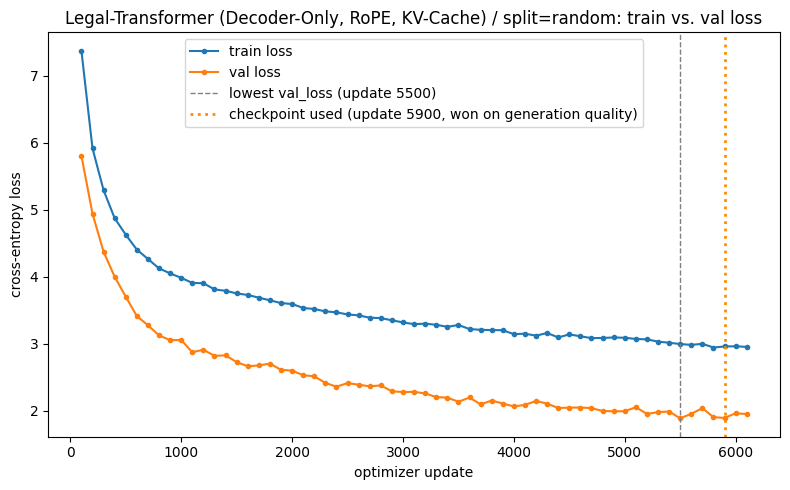

saved: /kaggle/working/loss_curve_legal_transformer_random_moredata.png
final train_loss=2.9528 (ppl=19.16)  final val_loss=1.9499 (ppl=7.03)  gap=-1.0029


In [17]:
# Plot training vs validation loss
phase_marker(11, "Plotting training vs. validation loss")
if len(loss_history) < 2:
    print("fewer than 2 validation checks recorded -- not enough points for a useful plot "
          "(this happens if STEPS_THIS_SPLIT < Settings.EVAL_EVERY). Skipping.")
else:
    import matplotlib.pyplot as plt
    steps_axis = [h["step"] for h in loss_history]
    train_curve = [h["train_loss"] for h in loss_history]
    val_curve = [h["val_loss"] for h in loss_history]
    lowest_val_loss_step = steps_axis[val_curve.index(min(val_curve))]
    selected_step = val_metrics["selected_checkpoint_step"]

    plt.figure(figsize=(8, 5))
    plt.plot(steps_axis, train_curve, label="train loss", marker="o", markersize=3)
    plt.plot(steps_axis, val_curve, label="val loss", marker="o", markersize=3)
    plt.axvline(lowest_val_loss_step, color="gray", linestyle="--", linewidth=1,
                label=f"lowest val_loss (update {lowest_val_loss_step})")
    if selected_step != lowest_val_loss_step:
        plt.axvline(selected_step, color="darkorange", linestyle=":", linewidth=2,
                    label=f"checkpoint used (update {selected_step}, won on generation quality)")
    plt.xlabel("optimizer update")
    plt.ylabel("cross-entropy loss")
    plt.title(f"{ARCH_NAME} / split={SPLIT_KEY}: train vs. val loss")
    plt.legend()
    plt.tight_layout()
    plot_path = os.path.join(WORK_DIR, f"loss_curve_{ARCH_SLUG}.png")
    plt.savefig(plot_path, dpi=110)
    plt.show()
    print(f"saved: {plot_path}")

    gap = val_curve[-1] - train_curve[-1]
    print(f"final train_loss={train_curve[-1]:.4f} (ppl={math.exp(train_curve[-1]):.2f})  "
          f"final val_loss={val_curve[-1]:.4f} (ppl={math.exp(val_curve[-1]):.2f})  gap={gap:.4f}")
    if gap > 0.5:
        print("  a large, still-growing gap here (even after early stopping) suggests the model "
              "is still prone to overfitting at this data/step scale -- consider more data, more "
              "dropout, or stronger weight decay next time.")

In [18]:
# Save the best model and its score
phase_marker(12, "Saving checkpoint and score record")
metric_used = "bertscore_f1" if val_metrics["bertscore_f1"] is not None else "rouge_l_f1"
metric_value = val_metrics["bertscore_f1"] if val_metrics["bertscore_f1"] is not None else val_metrics["rouge_l_f1"]

ckpt_path = os.path.join(CKPT_DIR, f"{ARCH_SLUG}_best_{split_name}.pt")
torch.save(best_state, ckpt_path)
ckpt_path_root = os.path.join(WORK_DIR, f"{ARCH_SLUG}_best_{split_name}.pt")
torch.save(best_state, ckpt_path_root)
print(f"saved: {ckpt_path}")
print(f"saved (also at {WORK_DIR} root): {ckpt_path_root}")

tokenizer_path = os.path.join(WORK_DIR, f"tokenizer_{ARCH_SLUG}_{split_name}.json")
tokenizer.save(tokenizer_path)
print(f"saved tokenizer: {tokenizer_path}")

score_record = {
    "architecture": ARCH_NAME, "arch_slug": ARCH_SLUG, "split_key": SPLIT_KEY,
    "split_name": split_name, "metric_name": metric_used, "metric_value": metric_value,
    "final_train_loss": val_metrics["final_train_loss"],
    "final_train_perplexity": val_metrics["final_train_perplexity"],
    "best_val_loss": val_metrics["best_val_loss"], "best_val_perplexity": val_metrics["best_val_perplexity"],
    "stopped_early": val_metrics["stopped_early"], "val_n": val_metrics["n"],
    "train_n": len(train_items), "dropout": Settings.DROPOUT,
    "selected_checkpoint_step": val_metrics["selected_checkpoint_step"],
    "selected_decoding_config": val_metrics["selected_decoding_config"],
    "checkpoint_comparison": val_metrics["checkpoint_comparison"],
    "decoding_comparison": val_metrics["decoding_comparison"],
}
score_path = os.path.join(WORK_DIR, f"score_{ARCH_SLUG}.json")
with open(score_path, "w", encoding="utf-8") as f:
    json.dump(score_record, f, indent=2)
print(f"score record: {score_path}")
print(f"\nValidation {metric_used} for this split is saved in the score record; the matching "
      f"checkpoint is used for the test predictions.")

best_model, _best_cfg = build_and_load_checkpoint(ckpt_path_root)
release_memory()


[Transformer | 12/13] Saving checkpoint and score record
saved: /kaggle/working/checkpoints/legal_transformer_random_moredata_best_random_90_10.pt
saved (also at /kaggle/working root): /kaggle/working/legal_transformer_random_moredata_best_random_90_10.pt
saved tokenizer: /kaggle/working/tokenizer_legal_transformer_random_moredata_random_90_10.json
score record: /kaggle/working/score_legal_transformer_random_moredata.json

Validation bertscore_f1 for this split is saved in the score record; the matching checkpoint is used for the test predictions.
    multi-GPU: using 2 GPUs via nn.DataParallel


In [ ]:
# Generate test predictions and make submission zip
phase_marker(13, "Generating official test predictions + packaging submission")
print(f"decoding config used for this final generation: {val_metrics['selected_decoding_config']} "
      f"(chosen empirically on held-out validation prompts in CELL 11 -- see its comparison table)")
predictions = {}
if len(official_prompts) > 0:
    continuations = batch_generate(best_model, tokenizer, official_prompts,
                                    batch_size=Settings.GEN_BATCH_SIZE, desc="official test set",
                                    **decode_kwargs_from_config(best_decode_cfg))
    for tid, cont in zip(official_ids, continuations):
        predictions[str(tid)] = {"text": cont}
    print(f"generated {len(predictions)} predictions (expected: every official test ID, doc 6.4)")
else:
    print("no test prompts available -- cannot generate predictions.")

if predictions:
    pred_path = os.path.join(OUT_DIR, "prediction.json")
    with open(pred_path, "w", encoding="utf-8") as f:
        json.dump(predictions, f, indent=2, ensure_ascii=False)
    pred_path_root = os.path.join(WORK_DIR, "prediction.json")
    with open(pred_path_root, "w", encoding="utf-8") as f:
        json.dump(predictions, f, indent=2, ensure_ascii=False)

    zip_path = os.path.join(OUT_DIR, f"submission_{ARCH_SLUG}.zip")
    with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
        zf.write(pred_path, arcname="prediction.json")
    zip_path_root = os.path.join(WORK_DIR, f"submission_{ARCH_SLUG}.zip")
    with zipfile.ZipFile(zip_path_root, "w", zipfile.ZIP_DEFLATED) as zf:
        zf.write(pred_path, arcname="prediction.json")
    print(f"submission: {zip_path_root}  (upload to Codabench ONLY if this split wins)")
    with zipfile.ZipFile(zip_path_root) as zf:
        print("zip contents:", [i.filename for i in zf.filelist])

print("\n" + "=" * 78)
print(f"SUMMARY -- {ARCH_NAME} / split={SPLIT_KEY}")
print("=" * 78)
print(f"trained split       : {split_name}")
print(f"parameters          : {n_params:,}")
print(f"corpus              : {len(corpus)} docs, by source {dict(source_counts)}")
print(f"local {metric_used:<15}: {metric_value:.4f}")
print(f"selected checkpoint : update {val_metrics['selected_checkpoint_step']} "
      f"(val_loss={val_metrics['best_val_loss']:.4f}, ppl={val_metrics['best_val_perplexity']})")
print(f"selected decoding   : {val_metrics['selected_decoding_config']}")
print(f"test coverage       : {len(predictions)} / {len(official_prompts)}")
print(f"\nfiles under {WORK_DIR}:")
print(f"  - {ckpt_path_root}")
print(f"  - {tokenizer_path}")
print(f"  - {score_path}")
print(f"  - {pred_path_root}")
print(f"  - {zip_path_root}")
print(f"\nRESUME LATER: upload {os.path.basename(ckpt_path_root)} + {os.path.basename(tokenizer_path)} "
      f"together as a Kaggle Dataset, attach it as input to a fresh copy of this notebook, and set "
      f"Settings.RESUME_CHECKPOINT_PATH / Settings.RESUME_TOKENIZER_PATH to skip straight to "
      f"decoding/checkpoint-quality experimentation next time (see CELL_SETTINGS's comment).")
print("\nDone. The test predictions are packaged in submission.zip and the "
      "validation score is saved in the score record "
      "(see above).")


[Transformer | 13/13] Generating official test predictions + packaging submission
decoding config used for this final generation: greedy (chosen empirically on held-out validation prompts in CELL 11 -- see its comparison table)


official test set:   0%|          | 0/63 [00:00<?, ?batch/s]

generated 1000 predictions (expected: every official test ID, doc 6.4)
submission: /kaggle/working/submission_legal_transformer_random_moredata.zip  (upload to Codabench ONLY if this split wins)
zip contents: ['prediction.json']

SUMMARY -- Legal-Transformer (Decoder-Only, RoPE, KV-Cache) / split=random
trained split       : random_90_10
parameters          : 271,180,672
corpus              : 93820 docs, by source {'acts': 18820, 'high_courts': 25000, 'supreme_court': 25000, 'tribunals': 25000}
local bertscore_f1   : 0.8307
selected checkpoint : update 5900 (val_loss=1.8920, ppl=6.632869672661509)
selected decoding   : greedy
test coverage       : 1000 / 1000

files under /kaggle/working:
  - /kaggle/working/legal_transformer_random_moredata_best_random_90_10.pt
  - /kaggle/working/tokenizer_legal_transformer_random_moredata_random_90_10.json
  - /kaggle/working/score_legal_transformer_random_moredata.json
  - /kaggle/working/prediction.json
  - /kaggle/working/submission_legal_transfo